In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
from pandas import DataFrame as df

In [3]:
data_path = '/content/drive/MyDrive/CPS_GUNDAM_DATA/'

#상반기 전체 그룹부문 IP 데이터 (완구 + 게임 + 영상 라이선스 + etc)
raw_train_1st_group = pd.read_csv(data_path + '1st_groupwide_gundam_sales_train.csv') #훈련용 상반기 전체 그룹 부문 IP 매출액 데이터
raw_test_1st_group = pd.read_csv(data_path + '1st_groupwide_gundam_sales_test.csv') #테스트용 상반기 전체 그룹 부문 IP 매출액 데이터

#데이터 전처리 1단계 결측값(NaN) 제거 (0으로 채우기)
train_1st_group = raw_train_1st_group.fillna(0) #훈련용 상반기 전체 그룹 부문 IP 매출액 데이터
test_1st_group = raw_test_1st_group.fillna(0) #테스트용 상반기 전체 그룹 부문 IP 매출액 데이터


In [4]:
#2026 데이터 제외-현재 수집중이기 때문에 데이터 오염을 발생시킬 위혐이 존재하므로 데이터셋에서 제외 (inplace=True)로 대체
test_1st_group.drop(test_1st_group[test_1st_group['1st_half'] == 2026].index, inplace=True)

test_1st_group #테스트용 상반기 전체 그룹 부문 IP 매출액 데이터

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2021,45.4,2.7,63.0,0.0,3.3,14.1,3.8,0.0,10.3,...,0.0,0.0,0.0,19.9,0.0,0.0,0.0,0.6,0.0,0.0
1,2022,50.2,2.6,61.2,0.0,3.1,13.3,4.2,0.0,11.7,...,0.0,0.0,0.0,21.6,0.0,0.0,0.0,1.3,0.0,0.0
2,2023,62.4,3.5,65.7,0.0,2.9,14.2,4.7,0.0,10.2,...,0.0,0.0,0.0,35.9,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,72.6,3.3,68.4,0.0,2.8,12.9,4.7,0.0,11.0,...,0.0,0.0,0.0,57.1,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,76.5,2.9,75.7,0.0,3.3,14.6,5.3,0.0,15.0,...,0.0,0.0,0.0,73.2,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
train_1st_group.head() #훈련용 상반기 전체 그룹 부문 IP 매출액 데이터

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2009,16.9,11.8,8.7,0.0,0.0,4.6,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.3
1,2010,17.0,8.4,5.8,0.0,0.0,8.9,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.9
2,2011,24.0,10.0,3.0,0.0,0.0,9.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0
3,2012,20.5,9.5,4.1,0.0,5.6,14.9,0.0,0.0,0.0,...,0.0,0.0,0.0,11.8,0.0,0.0,0.0,0.0,0.0,2.8
4,2013,31.7,8.8,0.0,0.0,6.2,14.0,0.0,0.0,0.0,...,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
test_1st_group.head() #테스트용 상반기 전체 그룹 부문 IP 매출액 데이터

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2021,45.4,2.7,63.0,0.0,3.3,14.1,3.8,0.0,10.3,...,0.0,0.0,0.0,19.9,0.0,0.0,0.0,0.6,0.0,0.0
1,2022,50.2,2.6,61.2,0.0,3.1,13.3,4.2,0.0,11.7,...,0.0,0.0,0.0,21.6,0.0,0.0,0.0,1.3,0.0,0.0
2,2023,62.4,3.5,65.7,0.0,2.9,14.2,4.7,0.0,10.2,...,0.0,0.0,0.0,35.9,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,72.6,3.3,68.4,0.0,2.8,12.9,4.7,0.0,11.0,...,0.0,0.0,0.0,57.1,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,76.5,2.9,75.7,0.0,3.3,14.6,5.3,0.0,15.0,...,0.0,0.0,0.0,73.2,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
#연도별 전체 그룹부문 IP 매출액 (완구 + 게임 + 영상 라이선스 + etc)
raw_train_FullYear_group = pd.read_csv(data_path + 'Full_year_groupwide_gundam_sales_train.csv') #훈련용 연도별 전체 그룹부문 IP 매출액 데이터
raw_test_FullYear_group = pd.read_csv(data_path + 'Full_year_groupwide_gundam_sales_test.csv') #테스트용 연도별 전체 그룹부문 IP 매출액 데이터

#데이터 전처리 1단계-결측값(NaN) 제거
train_FullYear_group = raw_train_FullYear_group.fillna(0) #훈련용 연도별 전체 그룹부문 IP 매출액 데이터
test_FullYear_group = raw_test_FullYear_group.fillna(0) #테스트용 연도별 전체 그룹부문 IP 매출액 데이터

In [8]:
#2026 이상 데이터 제외-현재 수집중이기 때문에 데이터 오염을 발생시킬 위혐이 존재하므로 데이터셋에서 제외 (inplace=True)로 대체
test_FullYear_group.drop(test_FullYear_group[test_FullYear_group['Full_Year'] >= 2026].index, inplace=True)

test_FullYear_group

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2021,95.0,5.2,127.4,0.0,6.6,28.9,8.7,0.0,21.4,...,0.0,0.0,0.0,38.0,0.0,0.0,0.0,2.0,0.0,0.0
1,2022,101.7,5.0,127.6,0.0,5.8,29.5,9.3,0.0,23.0,...,0.0,0.0,0.0,44.1,0.0,0.0,0.0,1.9,0.0,0.0
2,2023,131.3,6.5,144.5,0.0,5.6,32.1,9.9,0.0,18.7,...,0.0,0.0,0.0,86.3,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,145.7,6.5,140.6,0.0,6.4,31.5,10.1,0.0,25.3,...,0.0,0.0,0.0,112.1,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,153.5,6.4,190.6,0.0,7.9,30.7,11.4,0.0,26.9,...,0.0,0.0,0.0,139.5,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
train_FullYear_group.head() #훈련용 연도별 전체 그룹부문 IP 매출액 데이터

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2008,50.9,25.4,17.8,0.0,0.0,13.1,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.0
3,2009,42.8,25.6,15.8,0.0,11.3,10.4,0.0,0.0,0.0,...,0.0,0.0,0.0,4.6,0.0,0.0,0.0,0.0,0.0,13.0
4,2010,34.6,17.5,12.5,0.0,12.8,20.0,0.0,0.0,0.0,...,0.0,0.0,0.0,4.3,0.0,0.0,0.0,0.0,0.0,17.9


In [10]:
test_FullYear_group.head() #테스트용 연도별 전체 그룹부문 IP 매출액 데이터

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2021,95.0,5.2,127.4,0.0,6.6,28.9,8.7,0.0,21.4,...,0.0,0.0,0.0,38.0,0.0,0.0,0.0,2.0,0.0,0.0
1,2022,101.7,5.0,127.6,0.0,5.8,29.5,9.3,0.0,23.0,...,0.0,0.0,0.0,44.1,0.0,0.0,0.0,1.9,0.0,0.0
2,2023,131.3,6.5,144.5,0.0,5.6,32.1,9.9,0.0,18.7,...,0.0,0.0,0.0,86.3,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,145.7,6.5,140.6,0.0,6.4,31.5,10.1,0.0,25.3,...,0.0,0.0,0.0,112.1,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,153.5,6.4,190.6,0.0,7.9,30.7,11.4,0.0,26.9,...,0.0,0.0,0.0,139.5,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
#상반기 IP별 완구부문 매출액
raw_train_1st_toys = pd.read_csv(data_path + '1st_Toys_japan_gundam_sales_train.csv') # 학습(훈련)용 상반기 IP별 완구 부문 매출액 데이터
raw_test_1st_toys = pd.read_csv(data_path + '1st_Toys_japan_gundam_sales_test.csv') #테스트용 상반기 IP별 완구 부문 매출액 데이터

#데이터 전처리 1단계-결측값(NaN)제거
train_1st_toys=raw_train_1st_toys.fillna(0) #학습(훈련)용 상반기 IP별 완구 부문 매출액 데이터
test_1st_toys=raw_test_1st_toys.fillna(0) #테스트용 상반기 IP별 완구 부문 매출액 데이터

In [12]:
#2026 이상 데이터 제외-현재 수집중이기 때문에 데이터 오염을 발생시킬 위혐이 존재하므로 데이터셋에서 제외 (inplace=True)로 대체
test_1st_toys.drop(test_1st_toys[test_1st_toys['1st_half'] >= 2026].index, inplace=True)

test_1st_toys

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,20.6,2.4,7.4,0.0,3.3,11.9,3.7,0.0,0.0,2.3,2.9,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.0
1,2022,21.8,2.2,10.1,0.0,3.0,9.9,3.9,0.0,0.0,3.8,2.6,0.0,0.0,5.3,0.0,0.0,0.0,0.7,0.0
2,2023,30.1,2.9,12.0,0.0,2.9,9.5,4.3,0.0,0.0,4.7,4.1,0.0,0.0,12.3,0.0,0.0,0.0,0.0,0.0
3,2024,34.7,2.8,12.2,0.0,2.8,9.4,4.3,0.0,0.0,4.3,5.9,0.0,0.0,30.0,0.0,0.0,0.0,0.0,0.0
4,2025,37.8,2.5,15.8,0.0,3.2,10.2,4.8,0.0,0.0,4.0,5.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
train_1st_toys.head() # 학습(훈련)용 상반기 IP별 완구 부문 매출액 데이터

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2009,7.0,6.2,1.9,0.0,5.5,3.8,4.1,0.0,0.0,2.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010,6.5,10.5,1.4,0.0,5.7,7.7,3.8,0.0,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011,6.6,7.0,1.0,0.0,6.0,8.0,4.2,0.0,0.0,1.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2012,6.5,7.5,2.1,1.6,5.2,13.3,4.3,0.0,0.0,0.8,0.0,0.0,0.0,5.6,1.9,1.2,1.3,0.0,0.0
4,2013,15.6,4.9,2.4,0.8,5.7,11.2,4.6,0.0,0.0,1.8,0.0,0.0,0.0,4.4,1.8,0.0,2.0,0.0,0.0


In [14]:
test_1st_toys.head() #테스트용 상반기 IP별 완구 부문 매출액 데이터

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,20.6,2.4,7.4,0.0,3.3,11.9,3.7,0.0,0.0,2.3,2.9,0.0,0.0,0.0,0.0,0.0,0.0,0.4,0.0
1,2022,21.8,2.2,10.1,0.0,3.0,9.9,3.9,0.0,0.0,3.8,2.6,0.0,0.0,5.3,0.0,0.0,0.0,0.7,0.0
2,2023,30.1,2.9,12.0,0.0,2.9,9.5,4.3,0.0,0.0,4.7,4.1,0.0,0.0,12.3,0.0,0.0,0.0,0.0,0.0
3,2024,34.7,2.8,12.2,0.0,2.8,9.4,4.3,0.0,0.0,4.3,5.9,0.0,0.0,30.0,0.0,0.0,0.0,0.0,0.0
4,2025,37.8,2.5,15.8,0.0,3.2,10.2,4.8,0.0,0.0,4.0,5.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
#연도별 IP별 완구 부문 매출액
raw_train_FullYear_toys = pd.read_csv(data_path + 'Full_year_Toys_japan_gundam_sales_train.csv') #학습(훈련)용 전체년도 IP별 완구부문 매출액 데이터
raw_test_FullYear_toys = pd.read_csv(data_path + 'Full_year_Toys_japan_gundam_sales_test.csv') #테스트용 전체년도 IP별 완구부문 매출액 데이터

#데이터 전처리 1단계-결측값(NaN) 제거
train_FullYear_toys= raw_train_FullYear_toys.fillna(0)
test_FullYear_toys= raw_test_FullYear_toys.fillna(0)

In [16]:
#2026 데이터 제외-현재 수집중이기 때문에 데이터 오염을 발생시킬 위혐이 존재하므로 데이터셋에서 제외 (inplace=True)로 대체
test_FullYear_toys.drop(test_FullYear_toys[test_FullYear_toys['Full_Year'] == 2026].index, inplace=True)

test_FullYear_toys

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,41.0,4.5,15.4,0.0,6.6,24.3,8.3,0.0,0.0,4.9,6.0,0.0,0.0,7.1,0.0,0.0,0.0,1.0,0.0
1,2022,44.2,4.4,19.7,0.0,5.7,22.8,8.7,0.0,0.0,8.0,5.9,0.0,0.0,10.0,0.0,0.0,0.0,1.0,0.0
2,2023,60.5,5.6,22.5,0.0,5.6,23.0,9.3,0.0,0.0,9.2,8.8,0.0,0.0,31.9,0.0,0.0,0.0,0.0,0.0
3,2024,68.7,5.4,23.0,0.0,6.4,23.4,9.4,0.0,0.0,8.3,11.9,0.0,0.0,60.3,0.0,0.0,0.0,0.0,0.0
4,2025,75.7,5.4,29.9,0.0,7.8,22.5,10.2,0.0,0.0,6.7,12.2,0.0,0.0,94.2,0.0,0.0,0.0,0.0,0.0


In [17]:
train_FullYear_toys.head() #학습(훈련)용 전체년도 IP별 완구부문 매출액 데이터

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2006,21.3,10.8,6.0,12.0,12.3,6.5,8.1,6.1,3.4,3.9,4.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2007,17.8,10.1,7.9,12.4,6.0,7.1,8.8,3.7,0.0,3.6,3.4,3.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2008,18.8,7.7,5.5,1.8,10.5,11.5,9.3,2.7,0.0,0.0,4.5,0.0,1.9,0.0,0.0,0.0,0.0,0.0,0.0
3,2009,16.0,12.0,3.7,0.0,10.5,8.7,9.1,0.0,0.0,4.3,3.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2010,14.4,10.5,3.0,0.0,11.9,17.5,8.4,0.0,0.0,3.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
test_FullYear_toys.head() # 테스트용 전체년도 IP별 완구부문 매출액 데이터

,Full_Year,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,41.0,4.5,15.4,0.0,6.6,24.3,8.3,0.0,0.0,4.9,6.0,0.0,0.0,7.1,0.0,0.0,0.0,1.0,0.0
1,2022,44.2,4.4,19.7,0.0,5.7,22.8,8.7,0.0,0.0,8.0,5.9,0.0,0.0,10.0,0.0,0.0,0.0,1.0,0.0
2,2023,60.5,5.6,22.5,0.0,5.6,23.0,9.3,0.0,0.0,9.2,8.8,0.0,0.0,31.9,0.0,0.0,0.0,0.0,0.0
3,2024,68.7,5.4,23.0,0.0,6.4,23.4,9.4,0.0,0.0,8.3,11.9,0.0,0.0,60.3,0.0,0.0,0.0,0.0,0.0
4,2025,75.7,5.4,29.9,0.0,7.8,22.5,10.2,0.0,0.0,6.7,12.2,0.0,0.0,94.2,0.0,0.0,0.0,0.0,0.0


In [19]:
#하반기(half_2nd) 전체 IP별 매출액 구하기
#상반기 그룹데이터는 2009년부터 시작함으로, 하반기 그룹 데이터도 2009년부터 시작해야함.

#-> 왜냐하면, 전체년도 데이터와 상반기 데이터의 행개수가 서로 다르기도 하고,
# 기준이 되는 연도('Full_year', '1st_half') 컬럼의 이름이 서로 상이하기 때문에 단순히 뺄셈 연산을 수행하면
#연도 매칭이 되지 않아 결측값(NaN)이 발생하기 때문이다.

#set_index('Full_year'): 연도별 그룹부문 iP 매출액 데이터의 연도를 인덱스로 지정하여 매칭한 후 뺄셈 수행 (공통 IP 컬럼 기준)
#set_index('1st_half'): 상반기 그룹 부문 IP별 매출액 데이터를 인덱스로 지정

#훈련 데이터
train_FullYear_temp = train_FullYear_group.set_index('Full_Year')
train_1st_temp = train_1st_group.set_index('1st_half')

#테스트 데이터
test_FullYear_temp = test_FullYear_group.set_index('Full_Year')
test_1st_temp = test_1st_group.set_index('1st_half')

# 하반기 전체 그룹 부문 IP별 매출액 계산 (FullYear - 1st_half) dropna로 결측치 제거후 index 이름 Half_2nd로 재정의함
#데이터 전처리 2단계- 인덱스 재정의 및 라벨링
train_2nd_group = (train_FullYear_temp - train_1st_temp).dropna().reset_index().rename(columns={'index': 'Half_2nd'}) #훈련용 하반기 전체년도 매출 데이터
test_2nd_group = (test_FullYear_temp - test_1st_temp).dropna().reset_index().rename(columns={'index': 'Half_2nd'}) #테스트용 하반기 전체년도 매출액 데이터

In [20]:
#하반기 토이부문 IP별 매출액 구하기
train_FullYear_toys_temp = train_FullYear_toys.set_index('Full_Year') #훈련용 전체년도 토이부문 데이터
train_1st_toys_temp = train_1st_toys.set_index('1st_half') #훈련용 상반기 토이부문 데이터

test_FullYear_toys_temp = test_FullYear_toys.set_index('Full_Year') #테스트용 전체년도 토이부문 데이터
test_1st_toys_temp = test_1st_toys.set_index('1st_half') #테스트용 상반기 토이부문 데이터

#동일한 원리로 데이터 전처리 2단계- 인덱스 재정의 및 라벨링
train_2nd_toy_group = (train_FullYear_toys_temp - train_1st_toys_temp).dropna().reset_index().rename(columns={'index': 'Half_2nd'}) #하반기 토이부문 데이터
test_2nd_toy_group = (test_FullYear_toys_temp - test_1st_toys_temp).dropna().reset_index().rename(columns={'index': 'Half_2nd'}) #테스트용 하반기 토이부문 데이터

In [21]:
#데이터 전처리 3단계: 위에서 구한 각 하반기 데이터셋에 대한 연도 칼럼 일관성 맞추기.

# 훈련용 하반기 전체 그룹부문 IP별 실제 매출액 데이터의 연도 칼럼명을 'Full_Year'에서 'Half_2nd'로 변경
train_2nd_group=train_2nd_group.rename(columns={'Full_Year':'Half_2nd'})

# 테스트용 하반기 전체 그룹부문 IP별 실제 매출액 데이터의 연도 칼럼명을 'Full_Year'에서 'Half_2nd'로 변경
test_2nd_group=test_2nd_group.rename(columns={'Full_Year':'Half_2nd'})

# 훈련용 하반기 토이부문 IP별 실제 매출액 데이터의 연도 칼럼명을 'Full_Year' 에서 'Half_2nd'로 변경
train_2nd_toy_group=train_2nd_toy_group.rename(columns={'Full_Year':'Half_2nd'})

# 테스트용 하반기 토이부문 IP별 실제 매출액 데이터의 연도 칼럼명을 'Full_Year' 에서 'Half_2nd'로 변경
test_2nd_toy_group=test_2nd_toy_group.rename(columns={'Full_Year':'Half_2nd'})


In [22]:
print("훈련 데이터 전체 년도별 실제 매출액 하반기 전체 그룹부문")
display(train_2nd_group.head())

print("테스트 데이터 전체 년도별 실제 매출액 하반기 전체 그룹부문")
display(test_2nd_group.head())

print("훈련 데이터 하반기 토이 부문")
display(train_2nd_toy_group.head())

print("테스트 데이터 하반기 토이 부문")
display(test_2nd_toy_group.head())


훈련 데이터 전체 년도별 실제 매출액 하반기 전체 그룹부문


,Half_2nd,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2009,25.9,13.8,7.1,0.0,11.3,5.8,0.0,0.0,0.0,...,0.0,0.0,0.0,4.6,0.0,0.0,0.0,0.0,0.0,8.7
1,2010,17.6,9.1,6.7,0.0,12.8,11.1,0.0,0.0,0.0,...,0.0,0.0,0.0,4.3,0.0,0.0,0.0,0.0,0.0,10.0
2,2011,14.2,3.7,5.3,0.0,13.5,17.4,0.0,0.0,0.0,...,0.0,0.0,0.0,15.4,0.0,0.0,0.0,0.0,0.0,6.0
3,2012,24.2,10.7,7.7,0.0,5.9,17.0,10.5,0.0,0.0,...,0.0,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0,4.9
4,2013,33.5,12.0,8.9,0.0,5.4,20.0,10.0,0.0,0.0,...,0.0,0.0,0.0,18.9,0.0,0.0,0.0,1.8,0.0,0.0


테스트 데이터 전체 년도별 실제 매출액 하반기 전체 그룹부문


,Half_2nd,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BEN10
0,2021,49.6,2.5,64.4,0.0,3.3,14.8,4.9,0.0,11.1,...,0.0,0.0,0.0,18.1,0.0,0.0,0.0,1.4,0.0,0.0
1,2022,51.5,2.4,66.4,0.0,2.7,16.2,5.1,0.0,11.3,...,0.0,0.0,0.0,22.5,0.0,0.0,0.0,0.6,0.0,0.0
2,2023,68.9,3.0,78.8,0.0,2.7,17.9,5.2,0.0,8.5,...,0.0,0.0,0.0,50.4,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,73.1,3.2,72.2,0.0,3.6,18.6,5.4,0.0,14.3,...,0.0,0.0,0.0,55.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,77.0,3.5,114.9,0.0,4.6,16.1,6.1,0.0,11.9,...,0.0,0.0,0.0,66.3,0.0,0.0,0.0,0.0,0.0,0.0


훈련 데이터 하반기 토이 부문


,Half_2nd,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2009,9.0,5.8,1.8,0.0,5.0,4.9,5.0,0.0,0.0,2.1,3.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010,7.9,0.0,1.6,0.0,6.2,9.8,4.6,0.0,0.0,1.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011,6.8,2.2,1.7,2.9,6.5,15.0,4.4,0.0,0.0,1.4,0.0,0.0,0.0,6.8,3.4,0.0,0.0,0.0,0.0
3,2012,9.1,5.5,2.3,2.4,5.5,15.0,5.3,0.0,0.0,1.0,0.0,0.0,0.0,5.6,2.9,1.1,2.3,0.0,0.0
4,2013,0.9,4.7,2.4,-0.8,4.9,15.9,5.4,0.0,0.0,0.2,0.0,0.0,0.0,3.9,-1.8,0.0,-2.0,1.5,0.0


테스트 데이터 하반기 토이 부문


,Half_2nd,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,20.4,2.1,8.0,0.0,3.3,12.4,4.6,0.0,0.0,2.6,3.1,0.0,0.0,7.1,0.0,0.0,0.0,0.6,0.0
1,2022,22.4,2.2,9.6,0.0,2.7,12.9,4.8,0.0,0.0,4.2,3.3,0.0,0.0,4.7,0.0,0.0,0.0,0.3,0.0
2,2023,30.4,2.7,10.5,0.0,2.7,13.5,5.0,0.0,0.0,4.5,4.7,0.0,0.0,19.6,0.0,0.0,0.0,0.0,0.0
3,2024,34.0,2.6,10.8,0.0,3.6,14.0,5.1,0.0,0.0,4.0,6.0,0.0,0.0,30.3,0.0,0.0,0.0,0.0,0.0
4,2025,37.9,2.9,14.1,0.0,4.6,12.3,5.4,0.0,0.0,2.7,7.1,0.0,0.0,94.2,0.0,0.0,0.0,0.0,0.0


In [23]:
#연도별 전체 그룹부문 IP별 회사 가이던스 계획 매출액
raw_train_plan_group = pd.read_csv(data_path + 'Plan_groupwide_gundam_sales_train.csv')
raw_test_plan_group = pd.read_csv(data_path + 'Plan_groupwide_gundam_sales_test.csv')

#데이터 전처리 1단계
train_plan_group = raw_train_plan_group.fillna(0)
test_plan_group = raw_test_plan_group.fillna(0)

In [24]:
train_plan_group.head() #훈련용 연도별 전체 그룹부문 IP별 회사 가이던스 계획 매출액 데이터
test_plan_group.head() #테스트용 연도별 전체 그룹부문 IP별 회사 가이던스 계획 매출액 데이터

,Plan,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,...,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch,BAN10
0,2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2022,103.0,5.0,127.0,0.0,7.0,29.5,9.5,0.0,16.5,...,0.0,0.0,0.0,38.0,0.0,0.0,0.0,2.5,0.0,0.0
2,2023,119.0,5.0,133.5,0.0,6.0,30.0,10.0,0.0,0.0,...,0.0,0.0,0.0,58.0,0.0,0.0,0.0,1.0,0.0,0.0
3,2024,135.0,7.0,130.0,0.0,6.0,32.0,10.0,0.0,23.0,...,0.0,0.0,0.0,78.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2025,145.0,6.5,145.0,0.0,6.0,32.0,10.5,0.0,23.0,...,0.0,0.0,0.0,105.0,0.0,0.0,0.0,0.0,0.0,0.0


In [25]:
#연도별 완구부문 IP별 매출액 데이터
raw_toy_train_plan = pd.read_csv(data_path + 'Plan_Toys_japan_gundam_sales_train.csv') #훈련용 완구부문 IP별 매출액 데이터
raw_toy_test_plan = pd.read_csv(data_path + 'Plan_Toys_japan_gundam_sales_test.csv') #테스트용 완구부문 IP별 매출액 데이터

#데이터 전처리 1단계
train_toy_plan = raw_toy_train_plan.fillna(0)
test_toy_plan = raw_toy_test_plan.fillna(0)


In [26]:
test_toy_plan

,Plan,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2022,24.5,5.0,13.0,0.0,7.0,24.5,9.0,0.0,0.0,6.0,6.0,0.0,0.0,7.0,0.0,0.0,0.0,1.0,0.0
2,2023,52.0,5.0,21.0,0.0,6.0,23.0,9.0,0.0,0.0,9.5,6.0,0.0,0.0,14.0,0.0,0.0,0.0,0.5,0.0
3,2024,62.0,6.0,20.0,0.0,6.0,23.0,9.0,0.0,0.0,9.5,9.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0
4,2025,70.0,5.0,27.0,0.0,6.0,23.0,9.5,0.0,0.0,9.0,11.5,0.0,0.0,64.0,0.0,0.0,0.0,0.0,0.0
5,2026,85.0,5.5,26.0,0.0,8.5,20.0,10.5,0.0,0.0,6.5,12.5,0.0,0.0,95.0,0.0,0.0,0.0,0.0,0.0
6,2027,110.0,6.0,29.0,0.0,9.5,6.0,11.0,0.0,0.0,6.0,15.0,0.0,0.0,96.0,0.0,0.0,0.0,0.0,0.0


In [27]:
train_toy_plan.head() #훈련용 완구부문 계획치 데이터

,Plan,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2007,20.0,10.0,4.5,9.5,9.0,7.5,7.5,5.0,4.0,3.5,3.0,2.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2008,19.0,10.0,6.0,6.5,8.5,9.0,8.5,3.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2009,17.0,10.0,4.5,1.5,11.5,11.0,9.5,2.0,0.0,5.5,3.0,0.0,1.5,0.0,0.0,0.0,0.0,0.0,0.0
4,2010,16.5,10.5,4.5,0.0,10.5,11.0,9.0,0.0,0.0,4.0,3.0,0.0,0.0,0.0,4.5,0.0,0.0,0.0,0.0


In [28]:
test_toy_plan.head() #테스트용 완구부문 계획치 데이터

,Plan,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2022,24.5,5.0,13.0,0.0,7.0,24.5,9.0,0.0,0.0,6.0,6.0,0.0,0.0,7.0,0.0,0.0,0.0,1.0,0.0
2,2023,52.0,5.0,21.0,0.0,6.0,23.0,9.0,0.0,0.0,9.5,6.0,0.0,0.0,14.0,0.0,0.0,0.0,0.5,0.0
3,2024,62.0,6.0,20.0,0.0,6.0,23.0,9.0,0.0,0.0,9.5,9.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0
4,2025,70.0,5.0,27.0,0.0,6.0,23.0,9.5,0.0,0.0,9.0,11.5,0.0,0.0,64.0,0.0,0.0,0.0,0.0,0.0


In [29]:
# EDA 진행
#선형회귀 모델을 fit하여 2025년 이후의 매출액을 예측하기 전에 해당, 각 데이터셋의 매출액 데이터가 시각화하기 적합한 데이터인지, 먼저 확인해야한다.
#동시에, 위에서 rename으로 Half_2nd라고 재정의한 인덱스가 칼럼에 정말로 적용이 되었는지 확인함

In [30]:
#EDA- 훈련데이터의 datetime 형식 확인하기 (계획치,실제 매출액데이터)
print("훈련용 계획치의 datetime 형식: ",train_toy_plan["Plan"].dtype )
print("훈련용 연도별 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",train_FullYear_group["Full_Year"].dtype)
print("훈련용 상반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",train_1st_group["1st_half"].dtype)
print("훈련용 하반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",train_2nd_group["Half_2nd"].dtype)
print("훈련용 연도별 토이부문 IP별 실제 매출액의 datetime 형식: ",train_FullYear_toys["Full_Year"].dtype)
print("훈련용 상반기 토이부문 IP별 실제 매출액의 datetime 형식: ", train_1st_toys["1st_half"].dtype)
print("훈련용 하반기 토이부문 IP별 실제 매출액의 datetime 형식: ", train_2nd_toy_group["Half_2nd"].dtype)
print("====================================================================================")
print("테스트용 계획치의 datetime 형식: ",test_toy_plan["Plan"].dtype )
print("테스트용 연도별 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",test_FullYear_group["Full_Year"].dtype)
print("테스트용 상반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",test_1st_group["1st_half"].dtype)
print("테스트용 하반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식: ",test_2nd_group["Half_2nd"].dtype)
print("테스트용 연도별 토이부문 IP별 실제 매출액의 datetime 형식: ",test_FullYear_toys["Full_Year"].dtype)
print("테스트용 상반기 토이부문 IP별 실제 매출액의 datetime 형식: ", test_1st_toys["1st_half"].dtype)
print("테스트용 하반기 토이부문 IP별 실제 매출액의 datetime 형식: ", test_2nd_toy_group["Half_2nd"].dtype)


훈련용 계획치의 datetime 형식:  int64
훈련용 연도별 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
훈련용 상반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
훈련용 하반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
훈련용 연도별 토이부문 IP별 실제 매출액의 datetime 형식:  int64
훈련용 상반기 토이부문 IP별 실제 매출액의 datetime 형식:  int64
훈련용 하반기 토이부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 계획치의 datetime 형식:  int64
테스트용 연도별 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 상반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 하반기 전체 그룹부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 연도별 토이부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 상반기 토이부문 IP별 실제 매출액의 datetime 형식:  int64
테스트용 하반기 토이부문 IP별 실제 매출액의 datetime 형식:  int64


In [31]:
#일자, 시간, 분, 초 데이터 파생변수는 원본데이터에서도 시,분,초가 포함되지 않았으므로 생략.
#그러나, 각각의 칼럼(열)에서 학습 데이터와 테스트 테이터가 특정 년도를 기준으로 적절하게 분리되었는지 재차 확인해야한다.

In [32]:
#훈련용 완구 판매 계획치 데이터의 datetime 칼럼(plan) 확인하기
train_toy_plan["Plan"]

,Plan
0,2006
1,2007
2,2008
3,2009
4,2010
5,2011
6,2012
7,2013
8,2014
9,2015


In [33]:
#훈련용 연도별 전체 그룹부문 IP별 실제 매출액 데이터의 datetime 칼럼 확인하기 (Full_Year)
train_FullYear_group["Full_Year"]

,Full_Year
0,2006
1,2007
2,2008
3,2009
4,2010
5,2011
6,2012
7,2013
8,2014
9,2015


In [34]:
#훈련용 연도별 토이부문 IP별 실제 매출액 데이터릐 datetime 칼럼 (1st_half)
train_FullYear_toys["Full_Year"]

,Full_Year
0,2006
1,2007
2,2008
3,2009
4,2010
5,2011
6,2012
7,2013
8,2014
9,2015


In [35]:
#훈련용 상반기 전체 그룹부문 IP별 훈련용 실제 매출액 데이터의 datetime 칼럼 (1st_half)
train_1st_group['1st_half']

,1st_half
0,2009
1,2010
2,2011
3,2012
4,2013
5,2014
6,2015
7,2016
8,2017
9,2018


In [36]:
#훈련용 상반기 토이부문 IP별 실제 매출 액데이터
train_1st_toys.head()

,1st_half,Mobile_Suit_Gundam,Power_Ranger_Series,DRAGON_BALL,Tamagotchi,Pretty_Cure,Kamen_Rider,Anpanman,Cinnamoroll,NARUTO,Ultraman,Pokemon,Digimon,Evangelion,ONE_PIECE,Battle_Spirits,TORIKO,The_Little_Battlers,Aikatsu!,Youkai_Watch
0,2009,7.0,6.2,1.9,0.0,5.5,3.8,4.1,0.0,0.0,2.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2010,6.5,10.5,1.4,0.0,5.7,7.7,3.8,0.0,0.0,1.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2011,6.6,7.0,1.0,0.0,6.0,8.0,4.2,0.0,0.0,1.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2012,6.5,7.5,2.1,1.6,5.2,13.3,4.3,0.0,0.0,0.8,0.0,0.0,0.0,5.6,1.9,1.2,1.3,0.0,0.0
4,2013,15.6,4.9,2.4,0.8,5.7,11.2,4.6,0.0,0.0,1.8,0.0,0.0,0.0,4.4,1.8,0.0,2.0,0.0,0.0


In [37]:
#훈련용 하반기 전체 그룹부문 IP별 실제 매출액 데이터의 datetime 칼럼 (Half_2nd)
train_2nd_group['Half_2nd']

,Half_2nd
0,2009
1,2010
2,2011
3,2012
4,2013
5,2014
6,2015
7,2016
8,2017
9,2018


In [38]:
#훈련용 하반기 토이부문 IP별 실제 매출액 데이터의 datetime 칼럼 (1st_half)
train_2nd_toy_group['Half_2nd']

,Half_2nd
0,2009
1,2010
2,2011
3,2012
4,2013
5,2014
6,2015
7,2016
8,2017
9,2018


In [39]:
#테스트용 완구 판매 계획치 데이터의 datetime 칼럼(plan)
test_toy_plan["Plan"]

,Plan
0,2021
1,2022
2,2023
3,2024
4,2025
5,2026
6,2027


In [40]:
#테스트용 연도별 전체 그룹부문 IP별 실제 매출액 데이터의 datetime 칼럼 (FullYear)
test_FullYear_group["Full_Year"]

,Full_Year
0,2021
1,2022
2,2023
3,2024
4,2025


In [41]:
#테스트용 연도별 토이부문 IP별 실제 매출액 데이터의 datetime 칼럼
test_FullYear_toys["Full_Year"]

,Full_Year
0,2021
1,2022
2,2023
3,2024
4,2025


In [42]:
#테스트용 상반기 전체 그룹부문 IP별 실제 매출액 데이터의 datetime 칼럼(1st_half)
test_1st_group["1st_half"]

,1st_half
0,2021
1,2022
2,2023
3,2024
4,2025


In [43]:
#테스트용 상반기 토이부문 IP별 실제 매출액 데이터의 datetime 컬럼(1st_half)
test_1st_toys["1st_half"]

,1st_half
0,2021
1,2022
2,2023
3,2024
4,2025


In [44]:
#테스트용 하반기 전체 IP별 실제 매출액 데이터의 datetime 칼럼(Half_2nd)
test_2nd_group["Half_2nd"]

,Half_2nd
0,2021
1,2022
2,2023
3,2024
4,2025


In [45]:
#테스트용 하반기 토이 부문 IP별 실제 매출액 데이터의 datetime 컬럼(Half_2nd)
test_2nd_toy_group["Half_2nd"]

,Half_2nd
0,2021
1,2022
2,2023
3,2024
4,2025


In [46]:
# EDA- 각 데이터셋의 datetime도 확인하였으므로, 시각화를 진행

In [47]:
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

<Axes: ylabel='Frequency'>

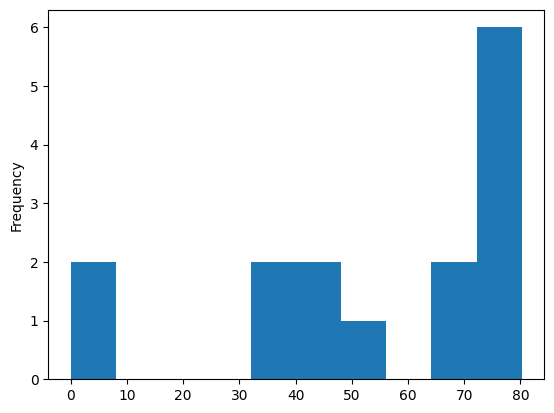

In [48]:
#훈련용 연도별 전체 그룹부문 IP중 건담 IP 매출액 분포도
train_FullYear_group["Mobile_Suit_Gundam"].plot.hist()
#x축은 건담 IP의 실제 연도간(2006~2020) 매출액 구간(0~10, 10~20, 30~40, 50~60, 70~80 구간 등)
#y축은 해당 매출액의 구간에 속하는 연도의 갯수, 빈도수

<Axes: ylabel='Frequency'>

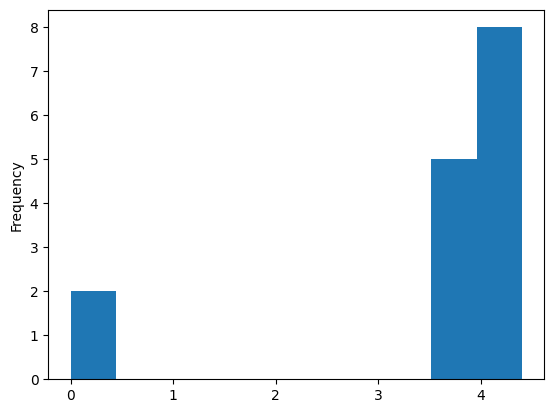

In [49]:
#그러나, 이상적인 목표변수(타겟값)를 찾기 위해서는 현재의 히스토그램이 정규 분포의 형태가 되도록 변형해야한다.
#그러나 현재 상태로 로그 변환시, 건담 IP 컬럼의 2006년, 2007년 매출액 데이터에 포함되어 있는 0의 값으로 인해, 로그 변환시 구하려는 예측값이 음의 무한대로 발산함
#reference: https://stackoverflow.com/questions/72927886/valueerror-supplied-range-of-inf-inf-is-not-finite
#따라서, np.log1p()을 통해서 해당 문제를 발생시키는 매출액 데이터를 완전한 0이 아닌, 0의 근사값으로 값을 변형해야한다.
#reference: https://suppppppp.github.io/posts/Why-Series-MDM-1/
#모델 학습시, 아래와 같이 로그변환된 x값과 y값을 사용하여 학습한다.
#단, 예측시에는 지수변환하여, 원본 값의 형태로 복원해야한다.
np.log1p(train_FullYear_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

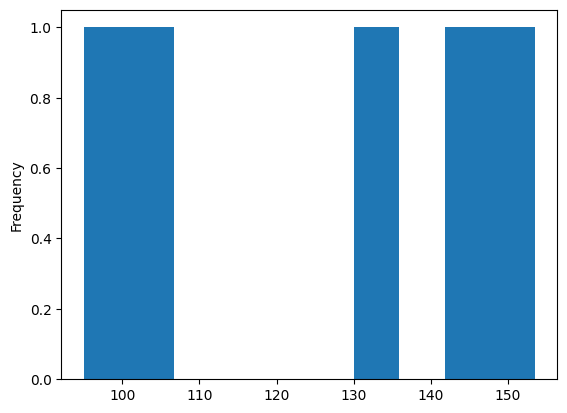

In [50]:
#테스트용(정답 데이터) 연도별 전체 그룹부문 IP중 건담 IP 매출액 분포도 (이미 충분히 정규 분포형태)
test_FullYear_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

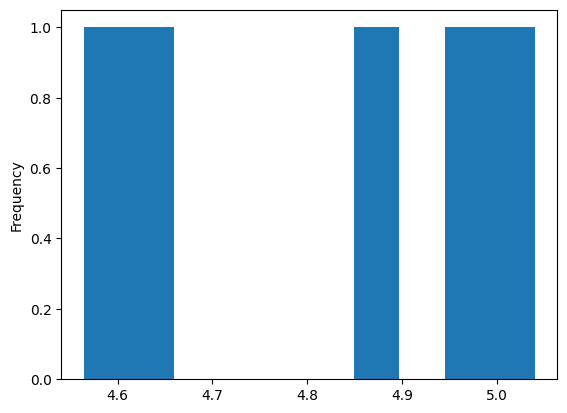

In [51]:
# 로그변환을 통한 테스트용 연도별 전체 그룹부문 건담IP 매출액 분포도 정규분포화 (결과 동일)
np.log1p(test_FullYear_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

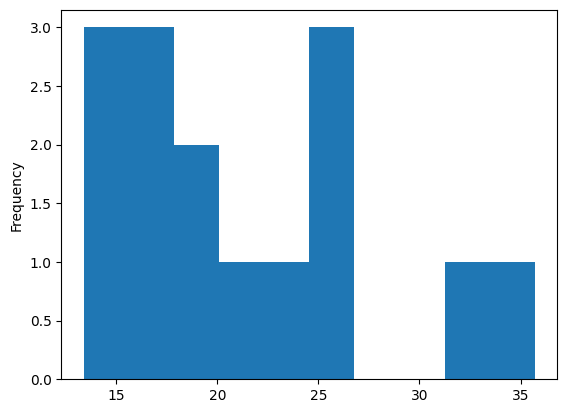

In [52]:
# 훈련용 연도별 토이부문 건담 IP 매출액 데이터 분포도
train_FullYear_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

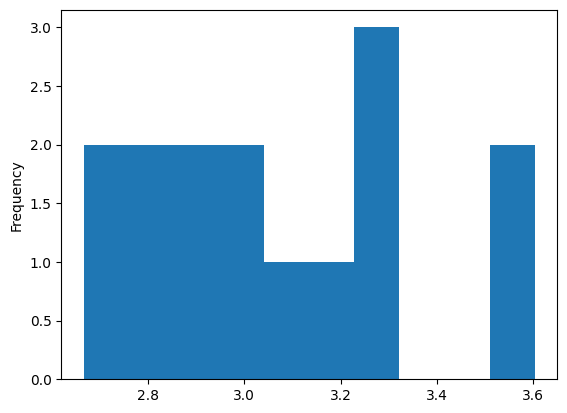

In [53]:
#로그 변환을 통한 연도별 토이부문 건담 IP 매출액 데이터 분포도 정규 분포화
np.log1p(train_FullYear_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

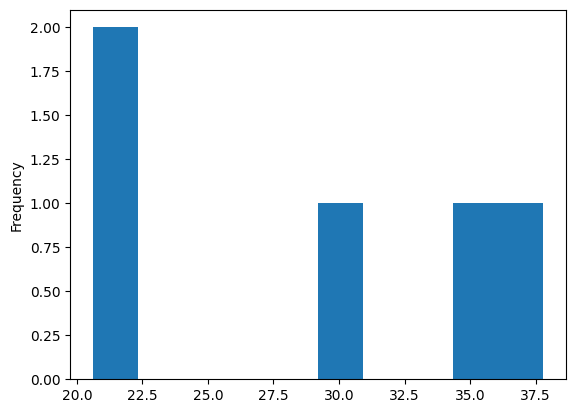

In [54]:
# 테스트용 연도별 토이부문 건담 IP 매출액 데이터
test_1st_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

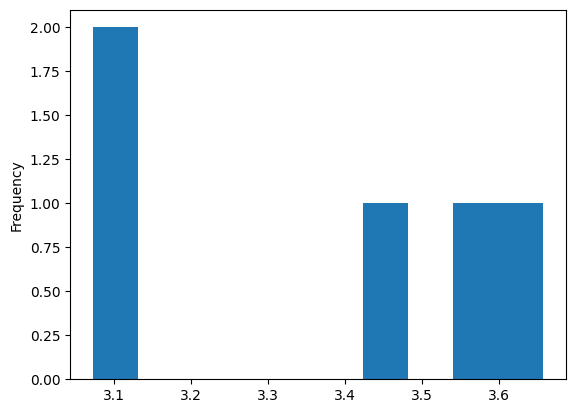

In [55]:
#로그 변환을 통한 테스트용 연도별 토이부문 건담 IP 매출액 데이터 정규분포화
np.log1p(test_1st_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

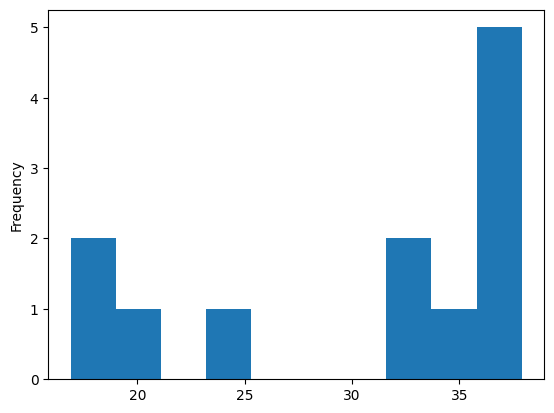

In [56]:
#훈련용 상반기 전체부문 건담 IP 매출액 데이터
train_1st_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

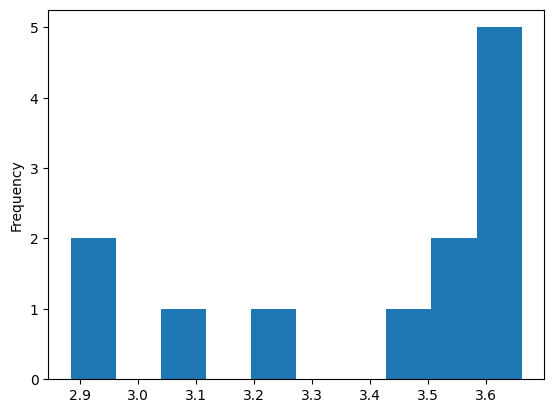

In [57]:
#로그 변환을 통한  상반기 전체부문 건담 IP 매출액 데이터 정규분포화
np.log1p(train_1st_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

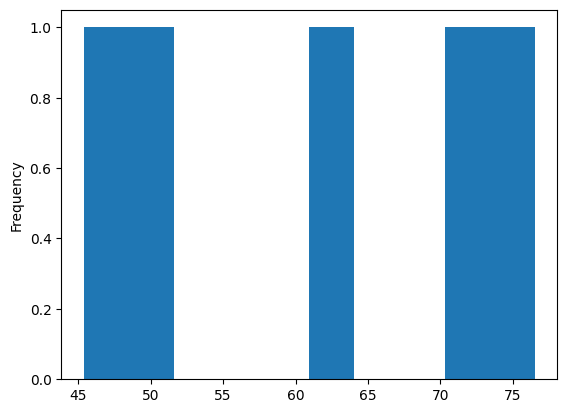

In [58]:
#테스트용 상반기 전체부문 건담 IP 매춝액 데이터
test_1st_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

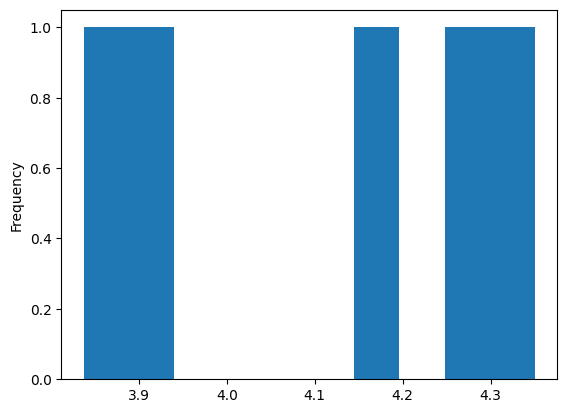

In [59]:
#로그변환을 통한 테스트용 상반기 전체부문 건담 IP 매출액 데이터 정규분포화
np.log1p(test_1st_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

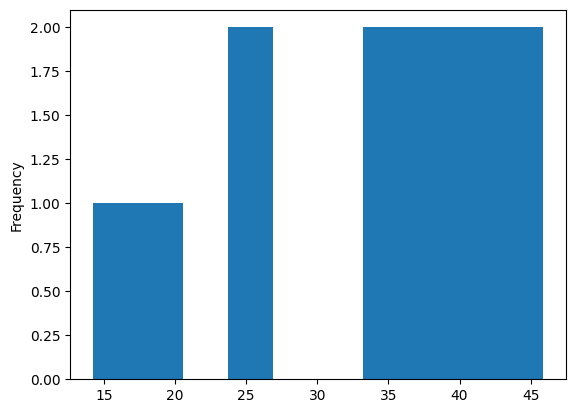

In [60]:
#훈련용 하반기 전체부문 건담 IP 매출액 데이터
train_2nd_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

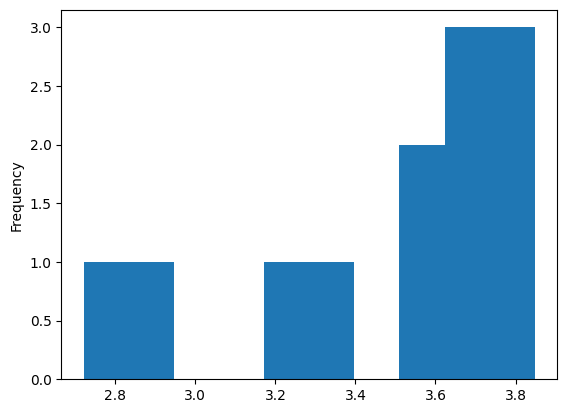

In [61]:
#로그변환을 통한 훈련용 하반기 전체부문 건담 IP 매출액 데이터
np.log1p(train_2nd_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

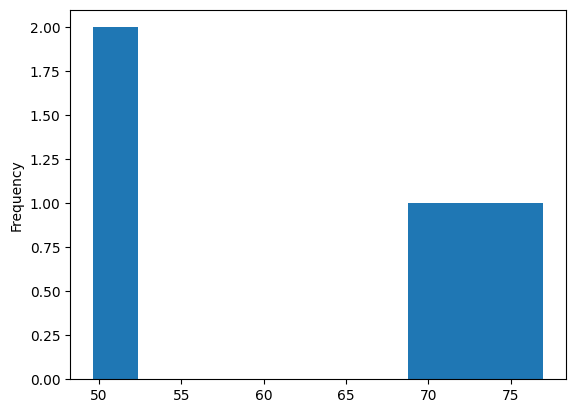

In [62]:
#테스트용 하반기 전체부문 건담 IP 매출액 데이터
test_2nd_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

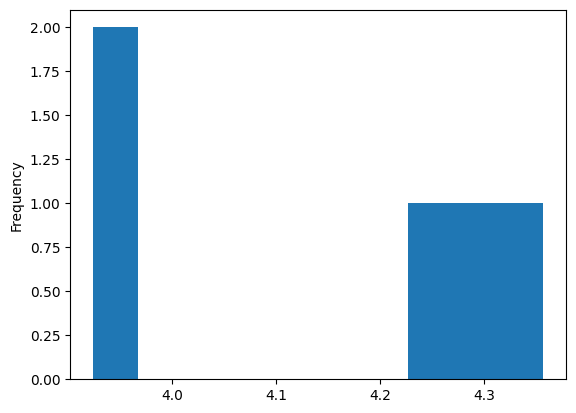

In [63]:
#로그 변환을 통한 테스트용 하반기 전체부문 건담 IP 매출액 데이터
np.log1p(test_2nd_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

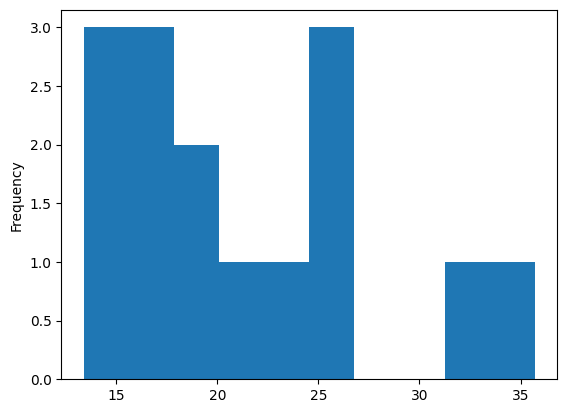

In [64]:
#훈련용 연도별 토이부문 건담 IP 매출액 데이터
train_FullYear_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

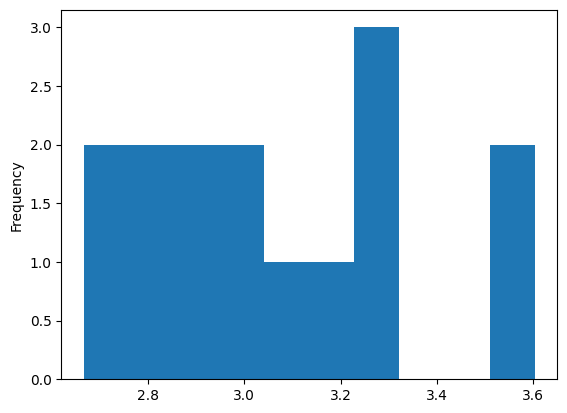

In [65]:
#로그변환을 통한 훈련용 연도별 토이부문 건담 IP 매출액 데이터 정규분포화
np.log1p(train_FullYear_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

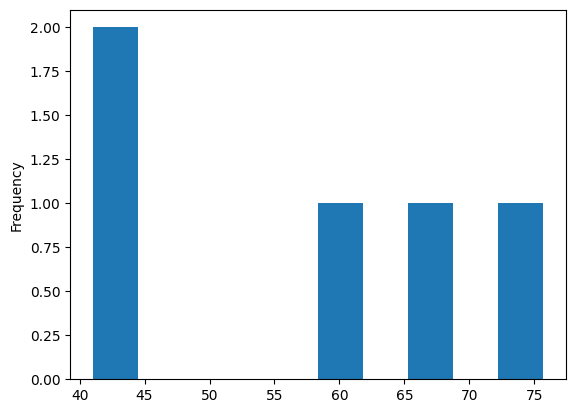

In [66]:
#테스트용 연도별 토이부문 건담 IP 매출액 데이터
test_FullYear_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

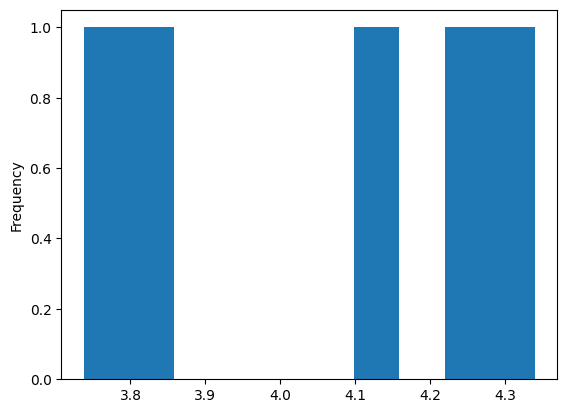

In [67]:
#로그변환을 통한 테스트용 연도별 토이부문 건담 IP 매출액 데이터의 정규 분포화
np.log1p(test_FullYear_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

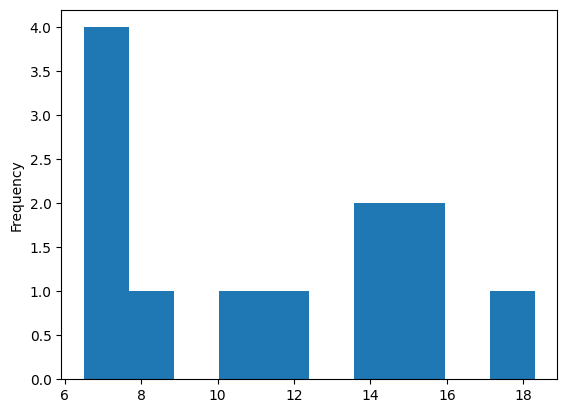

In [68]:
#훈련용 상반기 토이부문 건담 IP매출액 데이터
train_1st_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

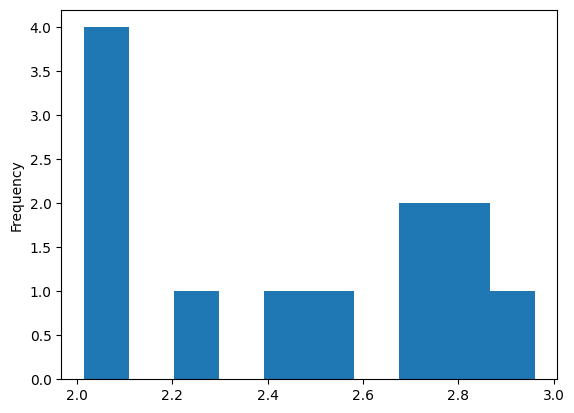

In [69]:
#로그변환을 통한 훈련용 상반기 토이부문 건담 IP 매출액 데이터의 정규분포화
np.log1p(train_1st_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

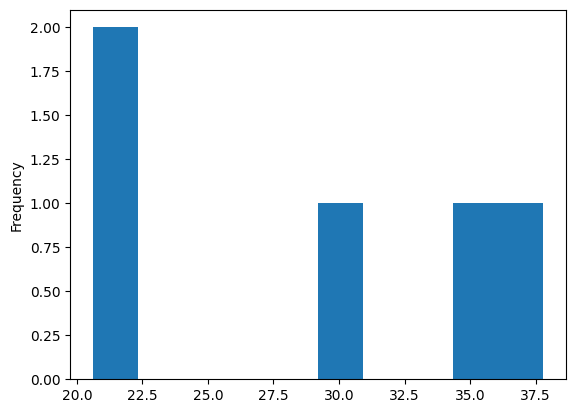

In [70]:
#테스트용 상반기 토이부문 건담 IP 매출액 데이터
test_1st_toys["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

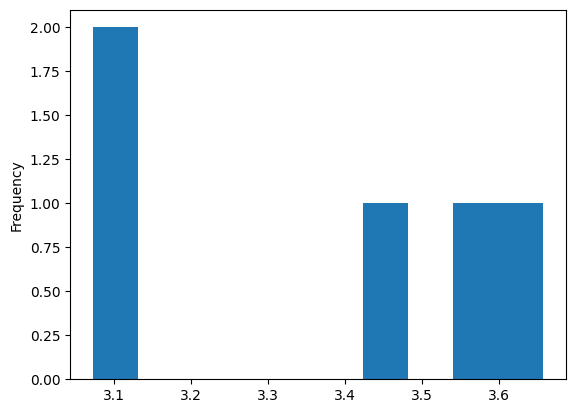

In [71]:
#로그변환을 통한 테스트용 상반기 토이부문 건담 IP 매출액 데이터 정규분포화
np.log1p(test_1st_toys["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

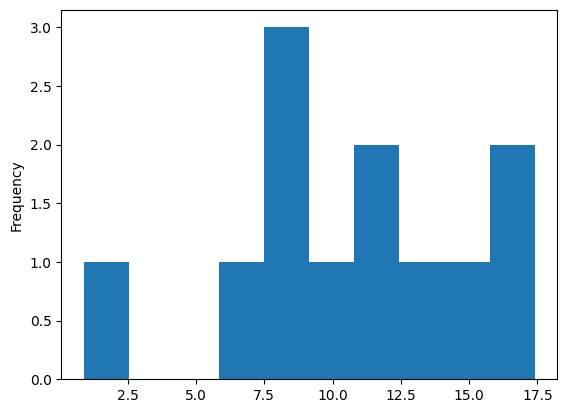

In [72]:
#훈련용 하반기 토이부문 건담 IP 매출액 데이터
train_2nd_toy_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

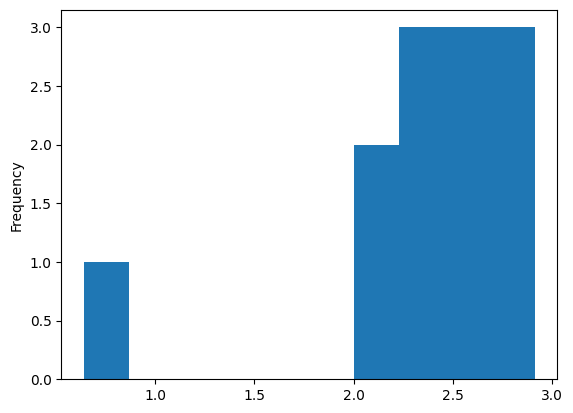

In [73]:
#로그변환을 통한 훈련용 하반기 토이부문 건담 IP 매출액 데이터
np.log1p(train_2nd_toy_group["Mobile_Suit_Gundam"]).plot.hist()

<Axes: ylabel='Frequency'>

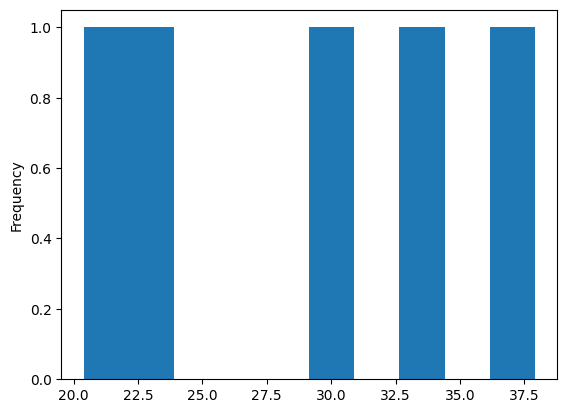

In [74]:
#테스트용 하반기 토이부문 건담 IP 매출액 데이터
test_2nd_toy_group["Mobile_Suit_Gundam"].plot.hist()

<Axes: ylabel='Frequency'>

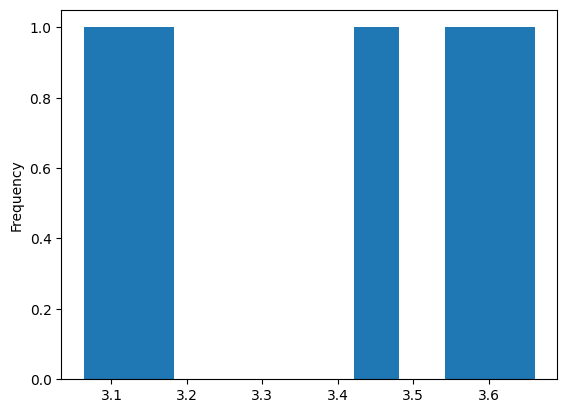

In [75]:
#테스트용 하반기 토이부문 건담 IP 매출액 데이터
np.log1p(test_2nd_toy_group["Mobile_Suit_Gundam"]).plot.hist()

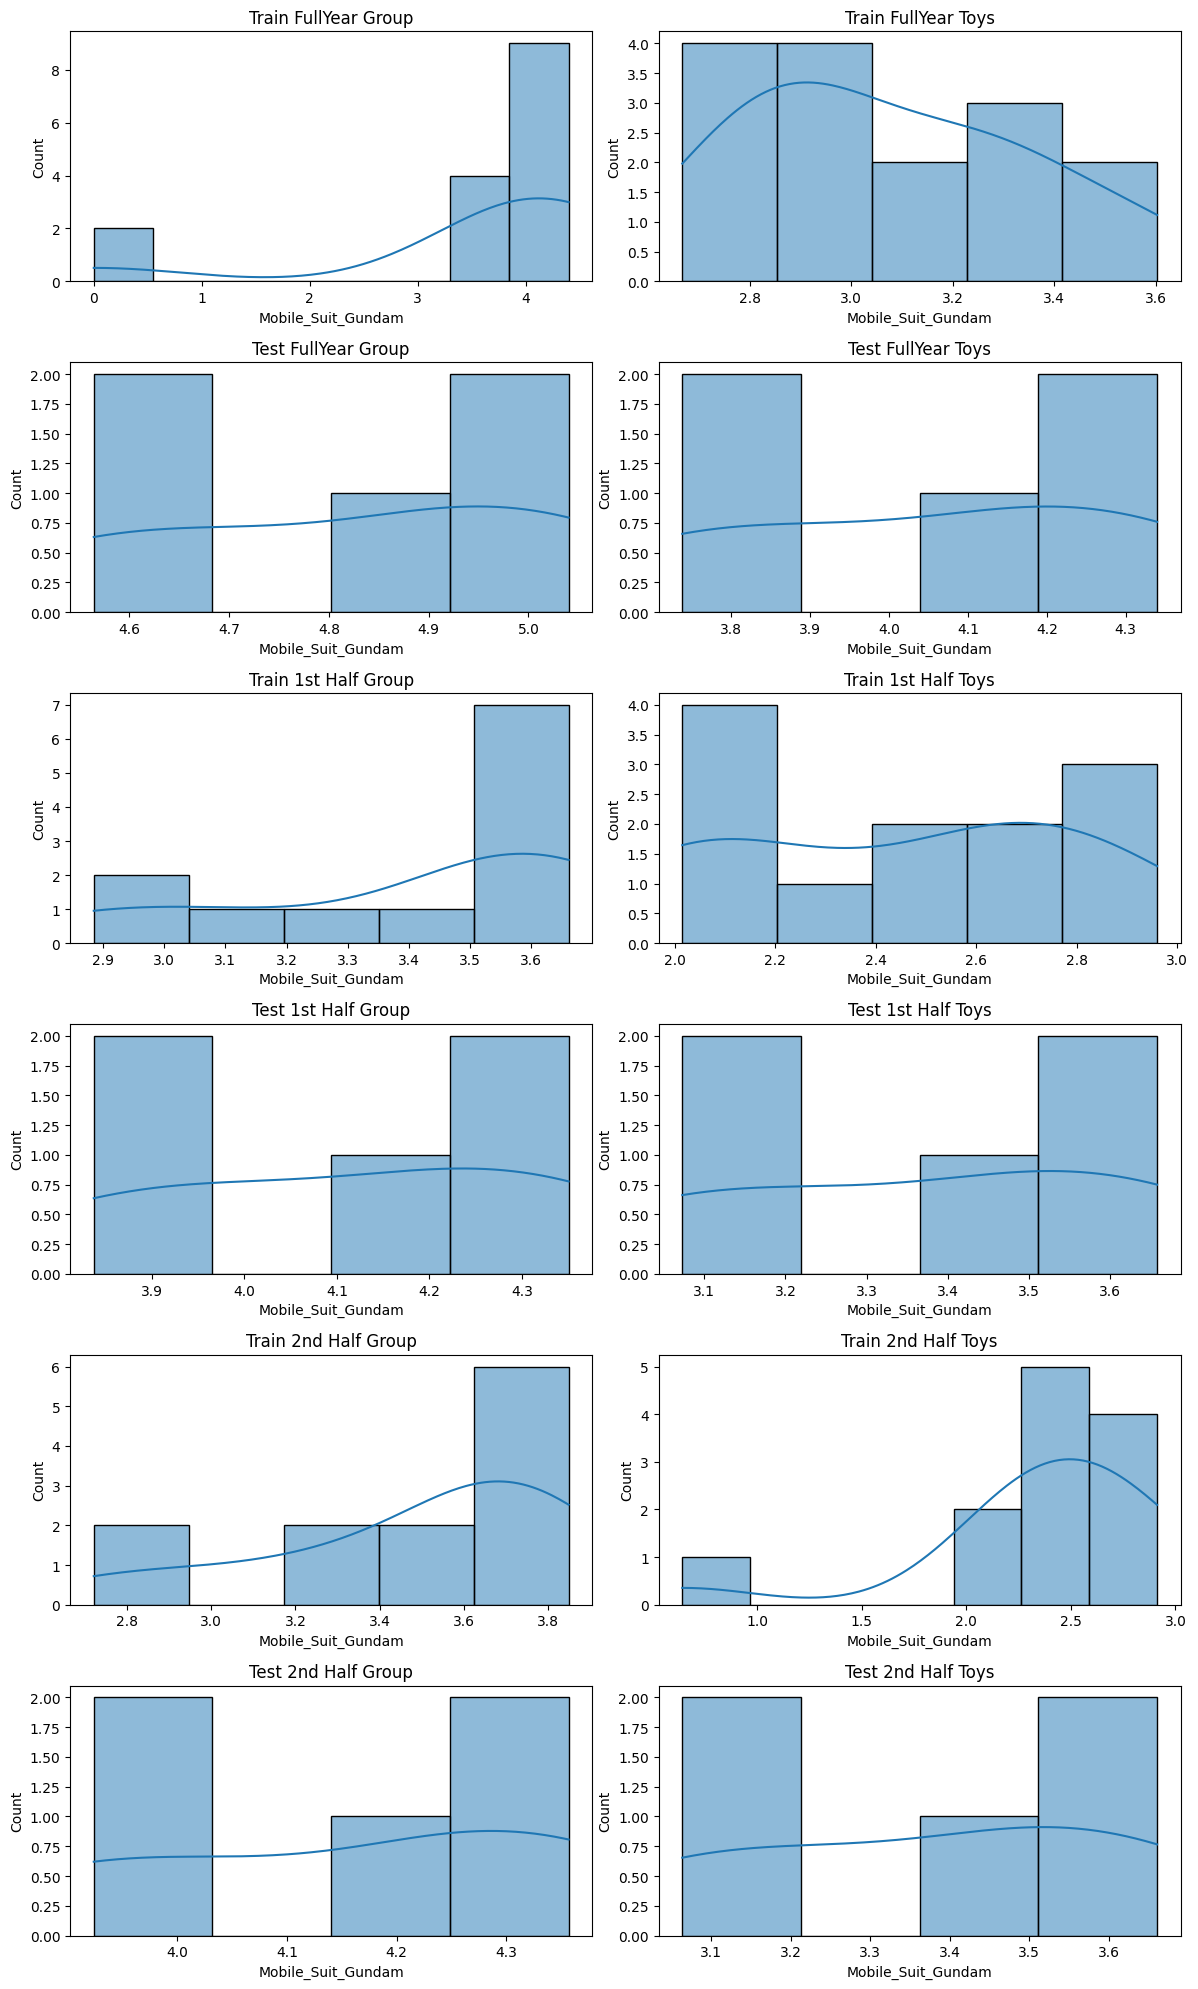

In [76]:
#Seabon 라이브러리를 통해 각 매출액 데이터셋별로 연도별 빈도수 히스토그램 가시화
#전체그룹부문(total_frequeny):{전체년도 훈련, 전체년도 테스트, 상반기 훈련, 상반기 테스트, 하반기 훈련, 하반기 테스트}
#토이부문(toy_frequency):{전체년도 훈련, 전체년도 테스트, 상반기 훈련, 상반기 테스트, 하반기 훈련, 하반기 테스트})

fig, axes = plt.subplots(6, 2, figsize=(12, 20))

# 1. 전체년도 (Full Year)
sns.histplot(data=np.log1p(train_FullYear_group["Mobile_Suit_Gundam"]), ax=axes[0, 0], kde=True)
axes[0, 0].set_title("Train FullYear Group")
sns.histplot(data=np.log1p(train_FullYear_toys["Mobile_Suit_Gundam"]), ax=axes[0, 1], kde=True)
axes[0, 1].set_title("Train FullYear Toys")

sns.histplot(data=np.log1p(test_FullYear_group["Mobile_Suit_Gundam"]), ax=axes[1, 0], kde=True)
axes[1, 0].set_title("Test FullYear Group")
sns.histplot(data=np.log1p(test_FullYear_toys["Mobile_Suit_Gundam"]), ax=axes[1, 1], kde=True)
axes[1, 1].set_title("Test FullYear Toys")

# 2. 상반기 (1st Half)
sns.histplot(data=np.log1p(train_1st_group["Mobile_Suit_Gundam"]), ax=axes[2, 0], kde=True)
axes[2, 0].set_title("Train 1st Half Group")
sns.histplot(data=np.log1p(train_1st_toys["Mobile_Suit_Gundam"]), ax=axes[2, 1], kde=True)
axes[2, 1].set_title("Train 1st Half Toys")

sns.histplot(data=np.log1p(test_1st_group["Mobile_Suit_Gundam"]), ax=axes[3, 0], kde=True)
axes[3, 0].set_title("Test 1st Half Group")
sns.histplot(data=np.log1p(test_1st_toys["Mobile_Suit_Gundam"]), ax=axes[3, 1], kde=True)
axes[3, 1].set_title("Test 1st Half Toys")

# 3. 하반기 (2nd Half)
sns.histplot(data=np.log1p(train_2nd_group["Mobile_Suit_Gundam"]), ax=axes[4, 0], kde=True)
axes[4, 0].set_title("Train 2nd Half Group")
sns.histplot(data=np.log1p(train_2nd_toy_group["Mobile_Suit_Gundam"]), ax=axes[4, 1], kde=True)
axes[4, 1].set_title("Train 2nd Half Toys")

sns.histplot(data=np.log1p(test_2nd_group["Mobile_Suit_Gundam"]), ax=axes[5, 0], kde=True)
axes[5, 0].set_title("Test 2nd Half Group")
sns.histplot(data=np.log1p(test_2nd_toy_group["Mobile_Suit_Gundam"]), ax=axes[5, 1], kde=True)
axes[5, 1].set_title("Test 2nd Half Toys")

plt.tight_layout()
plt.show()

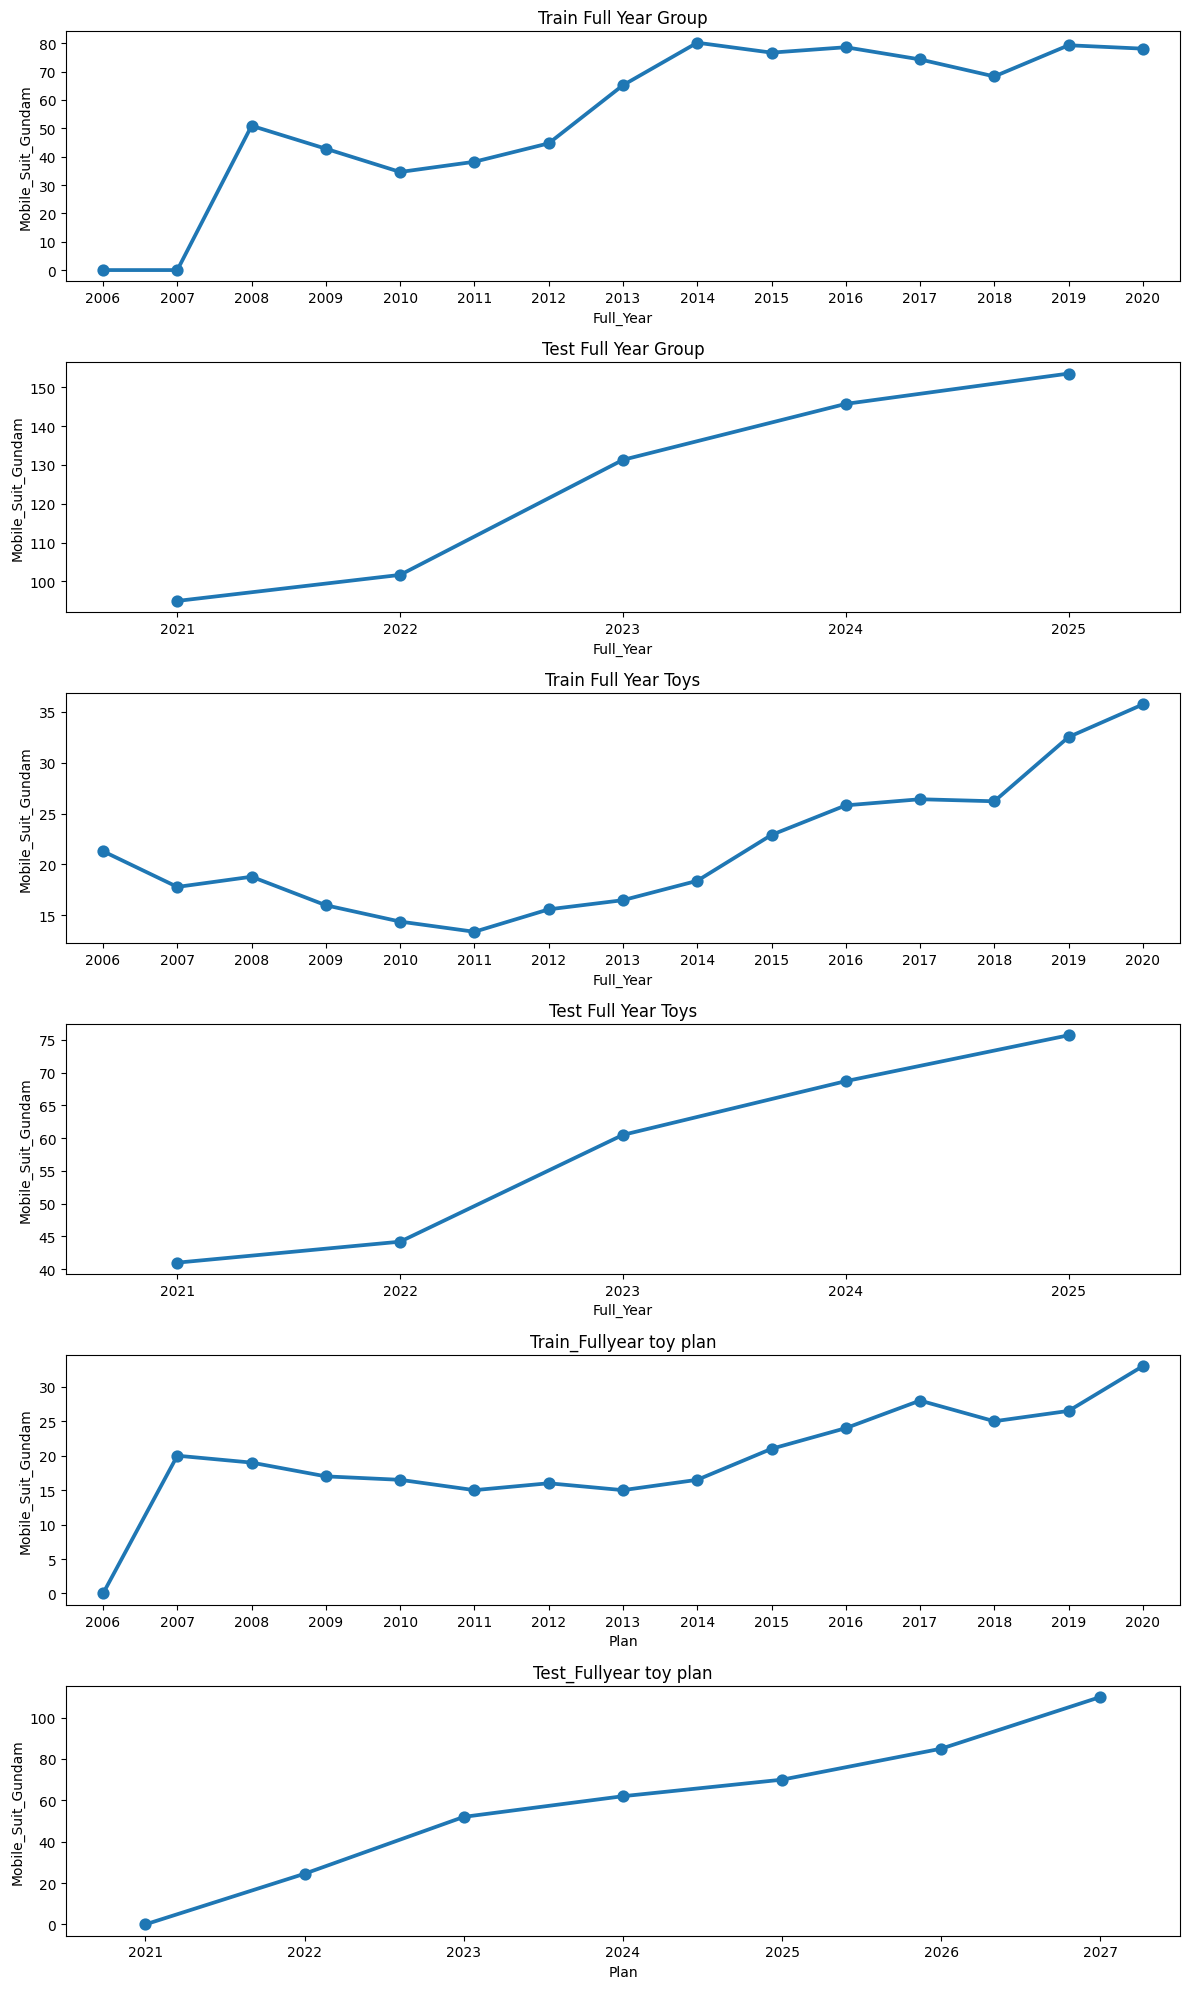

In [79]:
#포인트 플롯을 활용한 연도별 매출액 데이터 변동추이
figure, axes = plt.subplots(nrows=6)
figure.set_size_inches(12, 20)

sns.pointplot(data=train_FullYear_group, x="Full_Year", y="Mobile_Suit_Gundam", ax=axes[0])
axes[0].set_title("Train Full Year Group")

sns.pointplot(data=test_FullYear_group, x="Full_Year", y="Mobile_Suit_Gundam", ax=axes[1])
axes[1].set_title("Test Full Year Group")

sns.pointplot(data=train_FullYear_toys, x="Full_Year", y="Mobile_Suit_Gundam", ax=axes[2])
axes[2].set_title("Train Full Year Toys")

sns.pointplot(data=test_FullYear_toys, x="Full_Year", y="Mobile_Suit_Gundam", ax=axes[3])
axes[3].set_title("Test Full Year Toys")

sns.pointplot(data=train_toy_plan, x="Plan", y="Mobile_Suit_Gundam", ax=axes[4])
axes[4].set_title("Train_Fullyear toy plan")

sns.pointplot(data=test_toy_plan, x="Plan", y="Mobile_Suit_Gundam", ax=axes[5])
axes[5].set_title("Test_Fullyear toy plan")

plt.tight_layout()
plt.show()

#[분석결과]
#시계열 차트를 활용하여 EDA를 진행한 결과, 연도별 전체 그룹부문 건담 IP 매출은 2010년 중반 이래로 꾸준히 증가해왔으며
#특히나, 분리된 테스트 데이터에 포함된 2020년 이후의 건담 IP 매출액 데이터를 보면, 급진적으로 우상향하는 추이를 보임 (단 2026데이터는 현재 본사측에서 수집중이기 때문에 제외)
#이것은 분석인사이트중, 연도별 토이부문, 전체 그룹부문의 건담 IP의 매출액 데이터 지표를 근거로 팬데믹 시기에 걸쳐, 작년 2025년에 최고점(peak)을 돌파하였음을 알 수 있다.

Text(0.5, 1.0, 'Test 1st Half Toys')

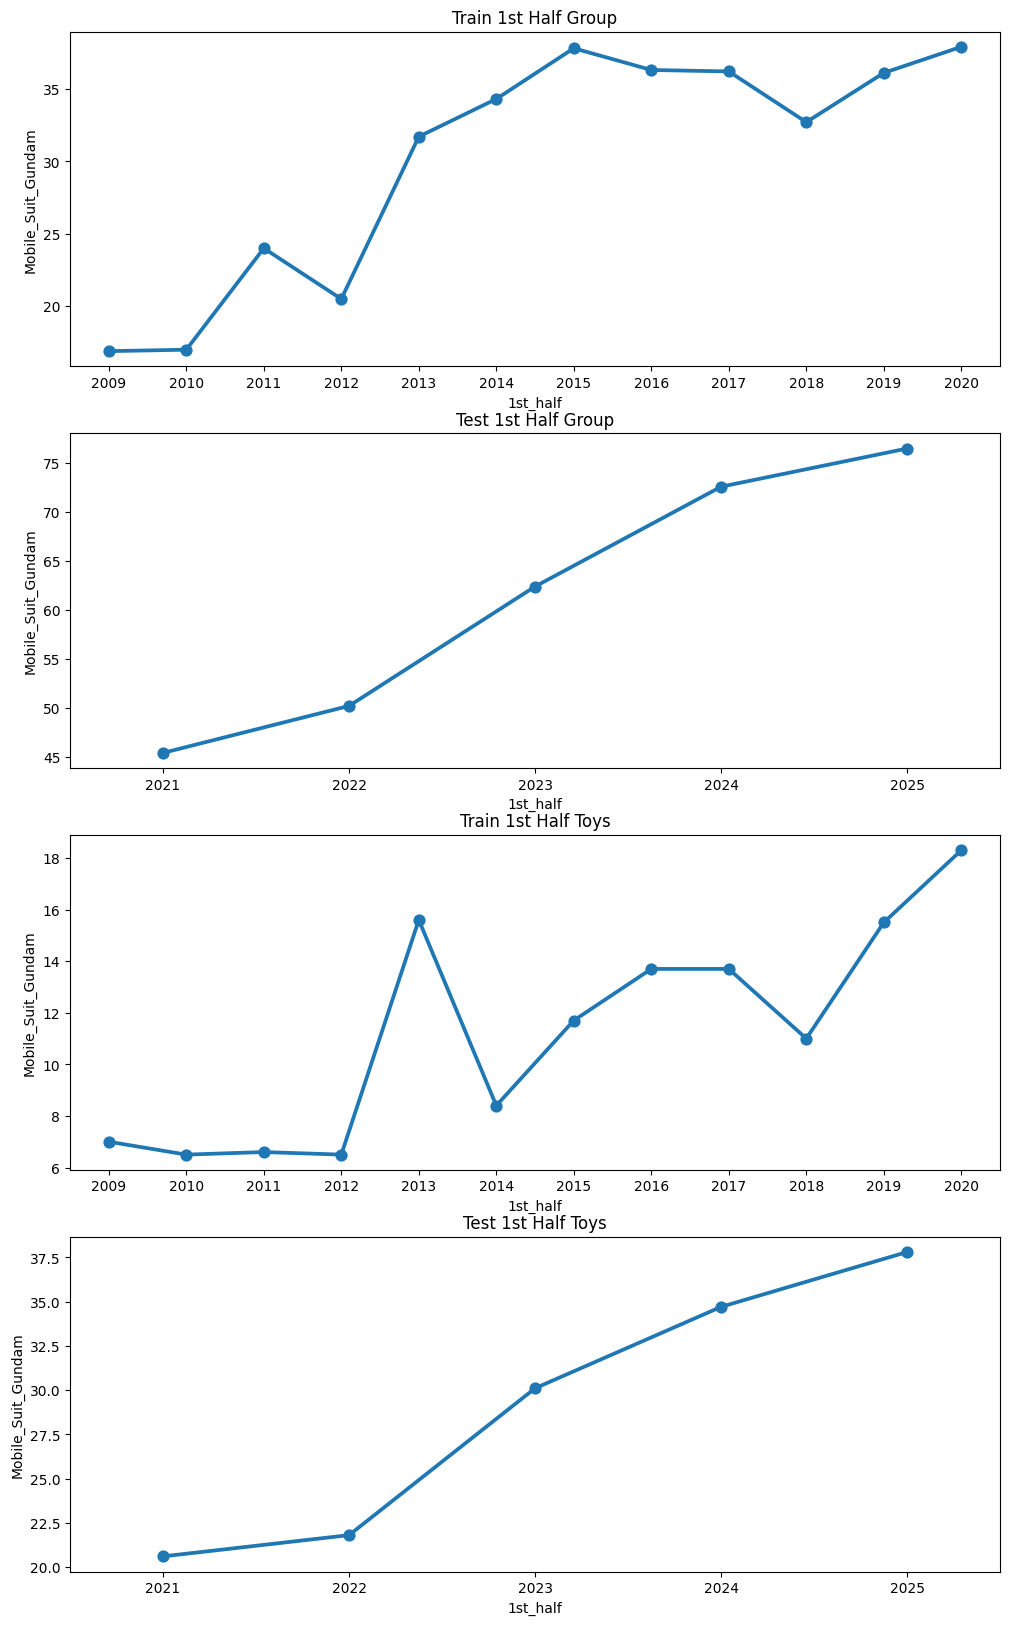

In [80]:
#포인트 플롯을 활용한 상반기 건담 IP 매출액 데이터
figure, axes = plt.subplots(nrows=4)
figure.set_size_inches(12, 20)

sns.pointplot(data=train_1st_group, x="1st_half", y="Mobile_Suit_Gundam", ax=axes[0])
axes[0].set_title("Train 1st Half Group")

sns.pointplot(data=test_1st_group, x="1st_half", y="Mobile_Suit_Gundam", ax=axes[1])
axes[1].set_title("Test 1st Half Group")

sns.pointplot(data=train_1st_toys, x="1st_half", y="Mobile_Suit_Gundam", ax=axes[2])
axes[2].set_title("Train 1st Half Toys")

sns.pointplot(data=test_1st_toys, x="1st_half", y="Mobile_Suit_Gundam", ax=axes[3])
axes[3].set_title("Test 1st Half Toys")



In [102]:
# 원본 훈련용 연도별 전체 그룹부문 건담 IP 매출액 데이터의 MSE와 로그변환 이후의 훈련용 연도별 전체 그룹 부문 건담 IP 매출액 데이터의 MSE 비교
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

# 1. 원본 데이터 기준 baseline 모델 생성 및 MSE 계산
# 독립 변수로 연도(Full_Year)를 사용하기 위해 2D array로 변환
X_train = train_FullYear_group[['Full_Year']]
y_train_raw = train_FullYear_group['Mobile_Suit_Gundam']

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse = mean_squared_error(y_train_raw, predict_raw)


# 2. 로그 변환 이후 MSE 계산
y_train_log = np.log1p(train_FullYear_group['Mobile_Suit_Gundam'])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

# 예측값을 원본 스케일로 역변환하여 복원한 뒤 실제 정답값(원본)과 비교하여 MSE 산출
#references: https://numpy.org/devdocs/reference/generated/numpy.expm1.html
return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

#[분석 결과]:연도별 전체 부문 건담 IP 매출액 데이터의 원본 MSE는 175.0835, 로그 변환 이후 복원된 MSE는 1471.7698이다.
#두 MSE 사이의 편차는 대략 1296.71로 왜곡이 많이 발생되었다. (즉, 손실함수가 크다.)

print(f"[원본 스케일]:{original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")
print(f"[원본 매출액 데이터의 MSE와 로그 변환 이후 다시 원본형태로 복원된 MSE 간의 편차]: {mse_log_transformed - original_mse}")

[원본 스케일]:175.0835
[로그 변환 이후]: [1.93986798 2.17158157 2.40329515 2.63500873 2.86672231 3.09843589
 3.33014948 3.56186306 3.79357664 4.02529022 4.25700381 4.48871739
 4.72043097 4.95214455 5.18385814]
[로그 변환 후 역변환]: 1471.7968
[원본 매출액 데이터의 MSE와 로그 변환 이후 복원된 MSE 간의 편차]: 1296.7133009060512


In [104]:
# 원본 훈련용 연도별 토이부문 건담 IP 매출액 데이터의 MSE와 로그변환 이후의 훈련용 연도별 토이부문 건담 IP 매출액 데이터의 MSE 비교

#1.원본 baseline 모델 생성 및 MSE 계산
X_train = train_FullYear_toys[['Full_Year']]
y_train_raw = train_FullYear_toys['Mobile_Suit_Gundam']

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse= mean_squared_error(y_train_raw, predict_raw)

#2.로그 변환 이후 MSE 계산
y_train_log = np.log1p(train_FullYear_toys['Mobile_Suit_Gundam'])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

#예측값 원본의 형태(지수함수)로 복원(np.expm1)
return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

print(f"[원본 스케일]: {original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")
print(f"[원본 매출액 데이터의 MSE와 로그 변환 이후 다시 원본형태로 복원된 MSE 간의 편차]: {original_mse - mse_log_transformed}")

#[분석결과]: 연도별 토이부문 건담 IP 매출액 데이터의 원본 MSE는 16.7912, 로그변환 이후 다시 지수로 복원한 MSE간의 편차는 2.45로
#훈련데이터중 연도별 전체부문 건담 IP 매출액 데이터의 두 MSE 간의 편차보다는 비교적 손실이 적다.



[원본 스케일]: 16.7912
[로그 변환 이후]: [2.74036834 2.78780308 2.83523783 2.88267258 2.93010733 2.97754208
 3.02497683 3.07241158 3.11984633 3.16728108 3.21471583 3.26215058
 3.30958533 3.35702008 3.40445483]
[로그 변환 후 역변환]: 14.3313
[원본 매출액 데이터의 MSE와 로그 변환 이후 다시 원본형태로 복원된 MSE 간의 편차]: 2.459910942884129


In [105]:
#원본 훈련용 상반기 전체그룹부문 건담 IP 매출액 데이터와 MSE 로그 변환 이후의 훈련용 상반기 전체 그룹부문 건담 IP 매출액 데이터 계산하기

#1. 원본 베이스라인 모델 생성 및 MSE 계산
X_train = train_1st_group[['1st_half']]
y_train_raw = train_1st_group['Mobile_Suit_Gundam']

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse = mean_squared_error(y_train_raw, predict_raw)

#2. 로그 변환 이후 MSE 계산
y_train_log = np.log1p(train_1st_group['Mobile_Suit_Gundam'])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

#예측값 원본의 형태(지수함수)로 복원(np.expm1)
return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

print(f"[원본 스케일]: {original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")
print(f"[원본 MSE와 로그 변환 후 다시 원본의 형태로 복원한 MSE간의 편차]{mse_log_transformed - original_mse}")

#[분석결과]: 산반기 전체 그룹부문의 건담 IP 매출액 데이터의 원본 MSE는 15.5407이고, 로그 변환 이후 다시 복원한 MSE는 21.364로
#두 MSE사이의 편차는 대략 5.82이다. 이는, 연도별 토이부문 건담 IP 매출액 데이터의 손실함수 보다는 크고, 연도별 전체부문 건담 IP 매출액 데이터의 손실 함수보다는 작은 수치이다.


[원본 스케일]: 15.5407
[로그 변환 이후]: [3.0082333  3.07945135 3.1506694  3.22188744 3.29310549 3.36432353
 3.43554158 3.50675962 3.57797767 3.64919572 3.72041376 3.79163181]
[로그 변환 후 역변환]: 21.3641
[원본 MSE와 로그 변환 후 다시 원본의 형태로 복원한 MSE간의 편차]5.823491232586511


In [106]:
#원본 훈련용 상반기 토이부문 건담 IP 매출액 데이터와 MSE 로그 변환 이후의 훈련용 상반기 토이부문 건담 IP 매출액 데이터 계산하기
#1. 원본 베이스라인 모델 생성 및 MSE 계산
X_train = train_1st_toys[["1st_half"]]
y_train_raw = train_1st_toys["Mobile_Suit_Gundam"]

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse = mean_squared_error(y_train_raw, predict_raw)

#2.로그변환 이후 MSE 계산
y_train_log = np.log1p(train_1st_toys["Mobile_Suit_Gundam"])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

print(f"[원본 스케일]: {original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")

[원본 스케일]: 5.3921
[로그 변환 이후]: [1.99837363 2.07977808 2.16118253 2.24258698 2.32399143 2.40539588
 2.48680034 2.56820479 2.64960924 2.73101369 2.81241814 2.8938226 ]
[로그 변환 후 역변환]: 5.4456
[원본 MSE와 로그 변환후 다시 원본의 형태로 복원한 MSE]0.05355800081531559


In [107]:
#원본 훈련용 하반기 전체부문 건담 IP  매출액데이터와 MSE 로그 변환 이후의 상반기 토이부문 건담 IP 매출액 데이터 계산하기

#1.원본 베이스라인 모델 생성 및 MSE 계산
X_train = train_2nd_group[["Half_2nd"]]
y_train_raw = train_2nd_group["Mobile_Suit_Gundam"]

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse = mean_squared_error(y_train_raw, predict_raw)

#2.로그변환 이후 MSE 계산
y_train_log = np.log1p(train_2nd_group["Mobile_Suit_Gundam"])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

print(f"[원본 스케일]: {original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")
print(f"[원본 MSE 와 로그 변환 이후 다시 원본의 형태로 복원한 MSE]:{mse_log_transformed - original_mse}")

#[분석결과]: 하반기 전체부문 건담 IP의 매출액 데이터의 원본 MSE는 42.3339이고, 로그 변환 후 다시 원본(지수)의 형태로 복원한 MSE는 50.1954이다.
# 따라서,두 MSE 사이의 편차는 7.86으로, 이는 연도별 전체 그룹부문보다는 여전히 작고, 연도별 토이 그룹부문, 상반기 전체그룹부문, 상반기 토이 그룹부문보다는 큰 손실함수이다.

[원본 스케일]: 42.3339
[로그 변환 이후]: [3.07116774 3.14580795 3.22044817 3.29508838 3.3697286  3.44436881
 3.51900902 3.59364924 3.66828945 3.74292967 3.81756988 3.89221009]
[로그 변환 후 역변환]: 50.1954
[원본 MSE 와 로그 변환 이후 다시 원본의 형태로 복원한 MSE]:7.861493912965734


In [108]:
#원본 훈련용 하반기 토이부문 건담 IP 매출액 데이터와 MSE 로그 변환 이후의 상반기 토이부문 건담 IP 매출액 데이터 계산하기

#1.원본 베이스라인 모델 선정 및 MSE 계산
X_train = train_2nd_toy_group[["Half_2nd"]]
y_train_raw = train_2nd_toy_group["Mobile_Suit_Gundam"]

model_for_EDA = LinearRegression()
model_for_EDA.fit(X_train, y_train_raw)
predict_raw = model_for_EDA.predict(X_train)
original_mse = mean_squared_error(y_train_raw, predict_raw)

#2 로그변환 이후 MSE 계산
y_train_log = np.log1p(train_2nd_toy_group["Mobile_Suit_Gundam"])

model_log = LinearRegression()
model_log.fit(X_train, y_train_log)
preds_log = model_log.predict(X_train)

return_original_mse = np.expm1(preds_log)
mse_log_transformed = mean_squared_error(y_train_raw, return_original_mse)

print(f"[원본 스케일]: {original_mse:.4f}")
print("======================================")
print(f"[로그 변환 이후]: {preds_log}")
print("======================================")
print(f"[로그 변환 후 역변환]: {mse_log_transformed:.4f}")
print(f"[원본 MSE와 로그 변환 이후 다시 원본의 형태로 복원한 MSE]: {original_mse - mse_log_transformed}")

#[분석결과]: 하반기 토이부문 건담 IP 매출액 데이터의 원본 MSE는 7.7585이고, 로그 변환 후 다시 원본(지수) 형태로 복원한 MSE는 7.2652 이다.
#그러므로 두 MSE 사이의 편차는 0.49로 연도별 전체그룹부문, 연도별 토이부문, 상반기 전체 그룹부문, 하반기 전체 그룹부문 건담 IP 매출액 데이터보다는 작고 상반기 토이부문 건담 IP 매출액 데이터보다는 손실함수가 한참은 크다.

[원본 스케일]: 7.7585
[로그 변환 이후]: [1.8558781  1.94532787 2.03477765 2.12422742 2.2136772  2.30312698
 2.39257675 2.48202653 2.5714763  2.66092608 2.75037586 2.83982563]
[로그 변환 후 역변환]: 7.2652
[원본 MSE와 로그 변환 이후 다시 원본의 형태로 복원한 MSE]: 0.4933006537339324


In [ ]:
#다음 EDA 2단계: 디지털부문, 영상 부문 복원치 계산하기